# Laboratorium 5 — MLflow

## Zadanie 3

In [1]:
import warnings

import mlflow
import mlflow.sklearn

warnings.filterwarnings("ignore")

mlflow.set_tracking_uri("http://localhost:5001")
print(f"Connected to MLflow at: {mlflow.get_tracking_uri()}")

Connected to MLflow at: http://localhost:5001


In [2]:
import numpy as np
import pandas as pd
from feature_engine.encoding import RareLabelEncoder
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

In [3]:
import subprocess
import yaml
from IPython.display import display


def get_git_commit():
    return subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()


def load_data(path):
    global df, df_train, df_test, y_train, y_test, dataset
    df = pd.read_parquet(path)
    df_train = df[df["YrSold"] < 2008].copy()
    df_test = df[df["YrSold"] == 2008].copy()
    y_train = df_train.pop("SalePrice")
    y_test = df_test.pop("SalePrice")
    with open(path + ".dvc") as f:
        metadata = yaml.safe_load(f)["outs"][0]
    dataset = mlflow.data.from_pandas(
        df, source=path, name="ames-2006-2008",
        digest=metadata["md5"], targets="SalePrice"
    )
    print("Dane:", df.shape, "DVC:", dataset.digest)


DATA_PATH = "data/ames_data_2006_2008.parquet"
load_data(DATA_PATH)
categorical_features = df_train.select_dtypes(include="object").columns
numerical_features = df_train.select_dtypes(exclude="object").columns

Dane: (1933, 80) DVC: f44053333f88a0646819936b37f000ee


In [4]:
median_imputer = SimpleImputer(strategy="median")
min_max_scaler = MinMaxScaler()
rare_encoder = RareLabelEncoder(tol=0.01, n_categories=0)
one_hot_encoder = OneHotEncoder(
    drop="first", sparse_output=False, handle_unknown="ignore"
)

num_pipeline = Pipeline(
    [("median_imputer", median_imputer), ("min_max_scaler", min_max_scaler)]
)

cat_pipeline = Pipeline(
    [("rare_encoder", rare_encoder), ("one_hot_encoder", one_hot_encoder)]
)

column_transformer = ColumnTransformer(
    [
        ("num_pipeline", num_pipeline, numerical_features),
        ("cat_pipeline", cat_pipeline, categorical_features),
    ],
    verbose_feature_names_out=False,
)

<Axes: ylabel='Frequency'>

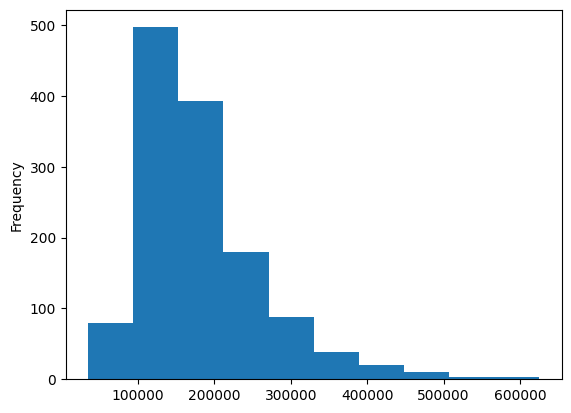

In [5]:
y_train.plot.hist()

<Axes: ylabel='Frequency'>

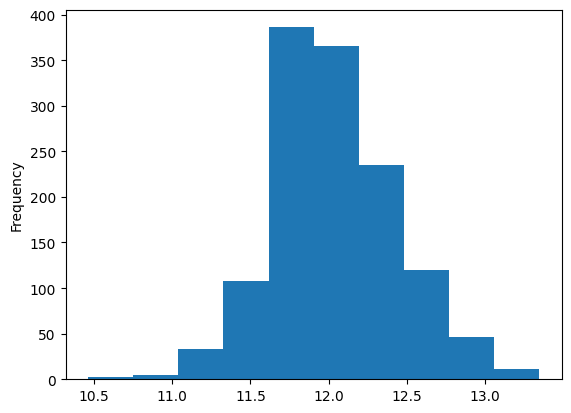

In [6]:
np.log1p(y_train).plot.hist()

In [7]:
AUTOLOG_KWARGS = {"log_input_examples": True, "log_datasets": False, "silent": True}

mlflow.sklearn.autolog(**AUTOLOG_KWARGS)

mlflow.set_experiment("ames-housing-autolog")

<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1794779213676, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794779213676, lifecycle_stage='active', name='ames-housing-autolog', tags={}, trace_location=None, workspace='default'>

In [8]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

models = [
    ("Ridge Regression", Ridge()),
    ("Decision Tree", DecisionTreeRegressor(max_depth=10, random_state=42)),
    ("K-Nearest Neighbors", KNeighborsRegressor(n_neighbors=10)),
    ("Random Forest", RandomForestRegressor(n_estimators=100, random_state=42)),
    ("Histogram Gradient Boosting", HistGradientBoostingRegressor(random_state=42)),
]


def make_pipeline(model) -> Pipeline:
    regressor = TransformedTargetRegressor(
        regressor=model, func=np.log1p, inverse_func=np.expm1
    )
    return Pipeline(
        [("preprocessing", clone(column_transformer)), ("model", regressor)]
    )

In [9]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error


def cross_validate_without_autolog(pipeline: Pipeline, X, y) -> np.ndarray:
    mlflow.sklearn.autolog(disable=True)
    try:
        return cross_val_score(pipeline, X, y, cv=5, scoring="r2")
    finally:
        mlflow.sklearn.autolog(**AUTOLOG_KWARGS)


def fit_sklearn_models(models, df_train, df_test, y_train, y_test):
    results = {}

    for model_name, model in models:
        pipeline = make_pipeline(model)

        with mlflow.start_run(run_name=model_name):
            mlflow.log_input(dataset, context="training")
            mlflow.set_tag("mlflow.source.git.commit", get_git_commit())
            cv_scores = cross_validate_without_autolog(pipeline, df_train, y_train)

            pipeline.fit(df_train, y_train)
            y_pred = pipeline.predict(df_test)

            metrics = {
                "cv_r2_mean": cv_scores.mean(),
                "cv_r2_std": cv_scores.std(),
                "test_rmse": root_mean_squared_error(y_test, y_pred),
                "test_mae": mean_absolute_error(y_test, y_pred),
                "test_r2": r2_score(y_test, y_pred),
            }
            mlflow.log_metrics(metrics)

            results[model_name] = metrics

            print(f"\n{model_name}:")
            print(f"  CV R^2 (mean ± std): {metrics['cv_r2_mean']:.3f} ± {metrics['cv_r2_std']:.3f}")
            print(f"  Test RMSE: {metrics['test_rmse']:.2f}")
            print(f"  Test MAE: {metrics['test_mae']:.2f}")
            print(f"  Test R^2: {metrics['test_r2']:.3f}")

    return results

In [10]:
sklearn_results = fit_sklearn_models(models, df_train, df_test, y_train, y_test)


Ridge Regression:
  CV R^2 (mean ± std): 0.912 ± 0.043
  Test RMSE: 20604.71
  Test MAE: 13581.70
  Test R^2: 0.926
🏃 View run Ridge Regression at: http://localhost:5001/#/experiments/1/runs/39a415c21a5f468881484dabcb26ab65
🧪 View experiment at: http://localhost:5001/#/experiments/1



Decision Tree:
  CV R^2 (mean ± std): 0.729 ± 0.075
  Test RMSE: 37219.61
  Test MAE: 23088.23
  Test R^2: 0.758
🏃 View run Decision Tree at: http://localhost:5001/#/experiments/1/runs/889cf71b23c84f82af165e1c2f0b392c
🧪 View experiment at: http://localhost:5001/#/experiments/1



K-Nearest Neighbors:
  CV R^2 (mean ± std): 0.620 ± 0.026
  Test RMSE: 39498.81
  Test MAE: 26313.65
  Test R^2: 0.727
🏃 View run K-Nearest Neighbors at: http://localhost:5001/#/experiments/1/runs/93015d386acc4f9d9dbbc527b47f5cbd
🧪 View experiment at: http://localhost:5001/#/experiments/1



Random Forest:
  CV R^2 (mean ± std): 0.861 ± 0.038
  Test RMSE: 25112.30
  Test MAE: 15542.91
  Test R^2: 0.890
🏃 View run Random Forest at: http://localhost:5001/#/experiments/1/runs/d9dab271e124419d8bc5915e4a0f69af
🧪 View experiment at: http://localhost:5001/#/experiments/1



Histogram Gradient Boosting:
  CV R^2 (mean ± std): 0.892 ± 0.039
  Test RMSE: 21765.65
  Test MAE: 13561.63
  Test R^2: 0.917
🏃 View run Histogram Gradient Boosting at: http://localhost:5001/#/experiments/1/runs/12356629bf334577bdb540d3dedf2555
🧪 View experiment at: http://localhost:5001/#/experiments/1


In [11]:
extra_models = [
    ("Ridge alpha=10", Ridge(alpha=10)),
    ("Random Forest leaf=2", RandomForestRegressor(n_estimators=100, min_samples_leaf=2, random_state=42)),
    ("Histogram Gradient Boosting l2=1", HistGradientBoostingRegressor(l2_regularization=1, random_state=42)),
]
sklearn_results.update(fit_sklearn_models(extra_models, df_train, df_test, y_train, y_test))
best_names = sorted(sklearn_results, key=lambda name: sklearn_results[name]["cv_r2_mean"], reverse=True)[:2]
best_models = [(name, model) for name, model in models + extra_models if name in best_names]
display(pd.DataFrame(sklearn_results).T.sort_values("cv_r2_mean", ascending=False))


Ridge alpha=10:
  CV R^2 (mean ± std): 0.906 ± 0.033
  Test RMSE: 20785.06
  Test MAE: 13839.12
  Test R^2: 0.924
🏃 View run Ridge alpha=10 at: http://localhost:5001/#/experiments/1/runs/366c132c33f64600bc6e3251646ea465
🧪 View experiment at: http://localhost:5001/#/experiments/1



Random Forest leaf=2:
  CV R^2 (mean ± std): 0.861 ± 0.038
  Test RMSE: 25067.64
  Test MAE: 15483.96
  Test R^2: 0.890
🏃 View run Random Forest leaf=2 at: http://localhost:5001/#/experiments/1/runs/2f8f5e18fedf43a1b08513a04d89f82b
🧪 View experiment at: http://localhost:5001/#/experiments/1



Histogram Gradient Boosting l2=1:
  CV R^2 (mean ± std): 0.888 ± 0.039
  Test RMSE: 22198.76
  Test MAE: 13698.80
  Test R^2: 0.914
🏃 View run Histogram Gradient Boosting l2=1 at: http://localhost:5001/#/experiments/1/runs/c167ac0d9735451188a4f33f3d3d7f68
🧪 View experiment at: http://localhost:5001/#/experiments/1


,cv_r2_mean,cv_r2_std,test_rmse,test_mae,test_r2
Ridge Regression,0.912160,0.043435,20604.708396,13581.704601,0.925695
Ridge alpha=10,0.906418,0.033436,20785.058491,13839.117238,0.924389
Histogram Gradient Boosting,0.891549,0.038527,21765.650624,13561.632361,0.917086
Histogram Gradient Boosting l2=1,0.888360,0.038860,22198.761265,13698.797818,0.913754
Random Forest leaf=2,0.861427,0.038421,25067.639687,15483.960206,0.890021
Random Forest,0.860827,0.037979,25112.302988,15542.912727,0.889629
Decision Tree,0.729422,0.074951,37219.610364,23088.228698,0.757547
K-Nearest Neighbors,0.619616,0.025708,39498.810594,26313.647784,0.726944


In [12]:
NEW_DATA_PATH = "data/ames_data_2006_2008_no_misc.parquet"
df.drop(columns="MiscVal").to_parquet(NEW_DATA_PATH, index=False)
subprocess.run([".venv/bin/dvc", "add", NEW_DATA_PATH], check=True)
subprocess.run(["git", "add", NEW_DATA_PATH + ".dvc"], check=True)
if subprocess.run(["git", "diff", "--cached", "--quiet", "--", NEW_DATA_PATH + ".dvc"]).returncode:
    subprocess.run(["git", "commit", "-m", "Track Ames data without MiscVal", "--", NEW_DATA_PATH + ".dvc"], check=True)
load_data(NEW_DATA_PATH)
numerical_features = df_train.select_dtypes(exclude="object").columns

⠋ Checking graph



To track the changes with git, run:

	git add data/ames_data_2006_2008_no_misc.parquet.dvc

To enable auto staging, run:

	dvc config core.autostage true


[master f69caad] Track Ames data without MiscVal
 1 file changed, 5 insertions(+)
 create mode 100644 lab05/data/ames_data_2006_2008_no_misc.parquet.dvc
Dane: (1933, 79) DVC: 8a6ea8fab6fdbe9b51b25d485500a224


In [13]:
median_imputer = SimpleImputer(strategy="median")
min_max_scaler = MinMaxScaler()
rare_encoder = RareLabelEncoder(tol=0.01, n_categories=0)
one_hot_encoder = OneHotEncoder(
    drop="first", sparse_output=False, handle_unknown="ignore"
)

num_pipeline = Pipeline(
    [("median_imputer", median_imputer), ("min_max_scaler", min_max_scaler)]
)

cat_pipeline = Pipeline(
    [("rare_encoder", rare_encoder), ("one_hot_encoder", one_hot_encoder)]
)

column_transformer = ColumnTransformer(
    [
        ("num_pipeline", num_pipeline, numerical_features),
        ("cat_pipeline", cat_pipeline, categorical_features),
    ],
    verbose_feature_names_out=False,
)

In [14]:
new_results = fit_sklearn_models(best_models, df_train, df_test, y_train, y_test)
display(pd.concat({"oryginalne": pd.DataFrame(sklearn_results).T.loc[best_names],
                   "bez MiscVal": pd.DataFrame(new_results).T}, names=["dane", "model"]))


Ridge Regression:
  CV R^2 (mean ± std): 0.912 ± 0.043
  Test RMSE: 20604.28
  Test MAE: 13581.47
  Test R^2: 0.926
🏃 View run Ridge Regression at: http://localhost:5001/#/experiments/1/runs/ff82883bef51462cb3cbb54a6fecca11
🧪 View experiment at: http://localhost:5001/#/experiments/1



Ridge alpha=10:
  CV R^2 (mean ± std): 0.906 ± 0.033
  Test RMSE: 20785.29
  Test MAE: 13839.21
  Test R^2: 0.924
🏃 View run Ridge alpha=10 at: http://localhost:5001/#/experiments/1/runs/3324ddddc6f34298b782046149596e6d
🧪 View experiment at: http://localhost:5001/#/experiments/1


cv_r2_mean  cv_r2_std     test_rmse  \
dane        model                                                   
oryginalne  Ridge Regression    0.912160   0.043435  20604.708396   
            Ridge alpha=10      0.906418   0.033436  20785.058491   
bez MiscVal Ridge Regression    0.912230   0.043490  20604.278891   
            Ridge alpha=10      0.906427   0.033425  20785.290210   

                                  test_mae   test_r2  
dane        model                                     
oryginalne  Ridge Regression  13581.704601  0.925695  
            Ridge alpha=10    13839.117238  0.924389  
bez MiscVal Ridge Regression  13581.472065  0.925698  
            Ridge alpha=10    13839.207929  0.924387

Nowa wersja usuwa `MiscVal`. Podział czasowy i domy testowe pozostają takie same. Najlepsze modele wybieram według średniego R² z walidacji krzyżowej. Dwa hashe DVC pozwalają porównać wersje danych w MLflow.

![Porównanie wersji danych w MLflow](screenshots/zadanie3_dane.png)

## Zadanie 4

In [15]:
load_data(DATA_PATH)
numerical_features = df_train.select_dtypes(exclude="object").columns

Dane: (1933, 80) DVC: f44053333f88a0646819936b37f000ee


In [16]:
median_imputer = SimpleImputer(strategy="median")
min_max_scaler = MinMaxScaler()
rare_encoder = RareLabelEncoder(tol=0.01, n_categories=0)
one_hot_encoder = OneHotEncoder(
    drop="first", sparse_output=False, handle_unknown="ignore"
)

num_pipeline = Pipeline(
    [("median_imputer", median_imputer), ("min_max_scaler", min_max_scaler)]
)

cat_pipeline = Pipeline(
    [("rare_encoder", rare_encoder), ("one_hot_encoder", one_hot_encoder)]
)

column_transformer = ColumnTransformer(
    [
        ("num_pipeline", num_pipeline, numerical_features),
        ("cat_pipeline", cat_pipeline, categorical_features),
    ],
    verbose_feature_names_out=False,
)

In [17]:
import copy

import torch
import torch.nn as nn
from tabm import TabM
from torch.utils.data import DataLoader, TensorDataset

mlflow.sklearn.autolog(disable=True)

mlflow.set_experiment("pytorch-housing-manual")

2026/11/15 23:01:20 INFO mlflow.tracking.fluent: Experiment with name 'pytorch-housing-manual' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/2', creation_time=1794780080958, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1794780080958, lifecycle_stage='active', name='pytorch-housing-manual', tags={}, trace_location=None, workspace='default'>

In [18]:
import mlflow.pytorch

torch.set_num_threads(2)

In [19]:
X_train = column_transformer.fit_transform(df_train)
X_test = column_transformer.transform(df_test)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, np.log1p(y_train), test_size=0.2, random_state=42
)

y_log_mean, y_log_std = y_tr.mean(), y_tr.std()


def to_tensors(X: np.ndarray, y_log: pd.Series) -> tuple[torch.Tensor, torch.Tensor]:
    y_standardized = (y_log.to_numpy() - y_log_mean) / y_log_std
    return (
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y_standardized, dtype=torch.float32).reshape(-1, 1),
    )


train_data = to_tensors(X_tr, y_tr)
val_data = to_tensors(X_val, y_val)
test_data = to_tensors(X_test, np.log1p(y_test))

print(f"Train: {len(X_tr)}, validation: {len(X_val)}, test: {len(X_test)}")
print(f"Number of features: {X_train.shape[1]}")

Train: 1049, validation: 263, test: 621
Number of features: 181


In [20]:
class HousePriceNet(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 128, dropout_rate: float = 0.2):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

In [21]:
def create_model(config: dict, n_features: int) -> nn.Module:
    if config["model"] == "mlp":
        return HousePriceNet(
            input_dim=n_features,
            hidden_dim=config["d_block"],
            dropout_rate=config["dropout"],
        )
    elif config["model"] == "tabm":
        return TabM.make(
            n_num_features=n_features,
            d_out=1,
            n_blocks=config["n_blocks"],
            d_block=config["d_block"],
            dropout=config["dropout"],
        )
    raise ValueError(f"Unknown model: {config['model']}")

In [22]:
class PyTorchTrainer:
    def __init__(self, config: dict):
        self.config = config

    @staticmethod
    def predict(model: nn.Module, X: torch.Tensor) -> torch.Tensor:
        return model(X).reshape(len(X), -1)

    def train_epoch(
        self, model: nn.Module, loader: DataLoader, optimizer: torch.optim.Optimizer
    ) -> float:
        model.train()
        total_loss = 0.0

        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            y_pred = self.predict(model, X_batch)
            loss = nn.functional.mse_loss(y_pred, y_batch.expand_as(y_pred))
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(X_batch)

        return total_loss / len(loader.dataset)

    @torch.no_grad()
    def evaluate(
        self, model: nn.Module, X: torch.Tensor, y: torch.Tensor
    ) -> dict[str, float]:
        model.eval()
        y_pred = self.predict(model, X).mean(dim=1, keepdim=True)

        y_pred_dollars = np.expm1(y_pred.numpy().ravel() * y_log_std + y_log_mean)
        y_true_dollars = np.expm1(y.numpy().ravel() * y_log_std + y_log_mean)

        return {
            "loss": nn.functional.mse_loss(y_pred, y).item(),
            "rmse": root_mean_squared_error(y_true_dollars, y_pred_dollars),
            "mae": mean_absolute_error(y_true_dollars, y_pred_dollars),
            "r2": r2_score(y_true_dollars, y_pred_dollars),
        }

    def fit(
        self,
        train_data: tuple[torch.Tensor, torch.Tensor],
        val_data: tuple[torch.Tensor, torch.Tensor],
    ) -> tuple[nn.Module, dict[str, float]]:
        torch.manual_seed(self.config["random_seed"])

        X_train, y_train = train_data
        model = create_model(self.config, n_features=X_train.shape[1])
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=self.config["learning_rate"],
            weight_decay=self.config["weight_decay"],
        )
        loader = DataLoader(
            TensorDataset(X_train, y_train),
            batch_size=self.config["batch_size"],
            shuffle=True,
        )

        best_metrics, best_state, best_epoch = None, None, 0
        for epoch in range(self.config["max_epochs"]):
            train_loss = self.train_epoch(model, loader, optimizer)
            val_metrics = self.evaluate(model, *val_data)

            mlflow.log_metrics(
                {
                    "train_loss": train_loss,
                    "val_loss": val_metrics["loss"],
                    "val_rmse": val_metrics["rmse"],
                },
                step=epoch,
            )

            if best_metrics is None or val_metrics["rmse"] < best_metrics["rmse"]:
                best_metrics, best_epoch = val_metrics, epoch
                best_state = copy.deepcopy(model.state_dict())
            elif epoch - best_epoch >= self.config["patience"]:
                break

        model.load_state_dict(best_state)
        mlflow.log_metric("best_epoch", best_epoch)
        mlflow.log_metrics({f"best_val_{name}": value for name, value in best_metrics.items()})

        return model, best_metrics

In [23]:
def train_and_log(config: dict) -> dict[str, float]:
    with mlflow.start_run(run_name=config["name"]):
        mlflow.log_params(config)

        trainer = PyTorchTrainer(config)
        model, val_metrics = trainer.fit(train_data, val_data)

        test_metrics = trainer.evaluate(model, *test_data)
        mlflow.log_metrics({f"test_{name}": value for name, value in test_metrics.items()})

        mlflow.pytorch.log_model(
            model, name=config["model"], input_example=val_data[0][:5].numpy()
        )

        print(
            f"{config['name']}: "
            f"validation RMSE {val_metrics['rmse']:.2f}, "
            f"test RMSE {test_metrics['rmse']:.2f}, "
            f"test R^2 {test_metrics['r2']:.3f}"
        )
        return test_metrics

In [24]:
base_config = {
    "random_seed": 42,
    "max_epochs": 200,
    "patience": 10,
    "batch_size": 64,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "dropout": 0.1,
}

mlp_config = base_config | {"name": "mlp_baseline", "model": "mlp", "d_block": 128}
tabm_config = base_config | {
    "name": "tabm_default",
    "model": "tabm",
    "n_blocks": 3,
    "d_block": 128,
}

for config in [mlp_config, tabm_config]:
    train_and_log(config)

2026/11/15 23:01:30 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /Users/marcinmalek/Documents/Codes/Projects/1_AGH/MLOps_examples/lab05


2026/11/15 23:01:31 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /Users/marcinmalek/Documents/Codes/Projects/1_AGH/MLOps_examples/lab05


2026/11/15 23:01:31 INFO mlflow.utils.environment: Detected uv project at /Users/marcinmalek/Documents/Codes/Projects/1_AGH/MLOps_examples/lab05. Attempting to export requirements via 'uv export'.


2026/11/15 23:01:31 INFO mlflow.utils.uv_utils: Exported 246 dependencies via uv


2026/11/15 23:01:31 INFO mlflow.utils.environment: Successfully exported 246 requirements from uv project. Skipping package capture based inference.


2026/11/15 23:01:31 INFO mlflow.utils.uv_utils: Extracted 1 private index URL(s) from uv.lock


... (8 outputs left out)

2026/11/15 23:01:43 INFO mlflow.utils.uv_utils: Extracted 1 private index URL(s) from uv.lock


2026/11/15 23:01:43 WARNING mlflow.utils.uv_utils: Private package indexes detected in uv lockfile. Ensure credentials are available at model load time via UV_INDEX_* environment variables or .netrc file.


2026/11/15 23:01:43 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


tabm_default: validation RMSE 21951.68, test RMSE 21637.24, test R^2 0.918
🏃 View run tabm_default at: http://localhost:5001/#/experiments/2/runs/17ec4cccf3d14f5781b552ec498218e8
🧪 View experiment at: http://localhost:5001/#/experiments/2


In [25]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)


def objective(trial: optuna.Trial) -> float:
    config = base_config | {
        "name": f"trial_{trial.number}",
        "model": "tabm",
        "n_blocks": trial.suggest_int("n_blocks", 1, 4),
        "d_block": trial.suggest_int("d_block", 64, 256),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [32, 64, 128, 256]),
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5),
    }

    with mlflow.start_run(run_name=config["name"], nested=True):
        mlflow.log_params(config)
        _, val_metrics = PyTorchTrainer(config).fit(train_data, val_data)

    return val_metrics["rmse"]


with mlflow.start_run(run_name="optuna_tabm"):
    study = optuna.create_study(
        direction="minimize", sampler=optuna.samplers.TPESampler(seed=42)
    )
    study.enqueue_trial(
        {"learning_rate": 1e-3, "dropout": 0.1, "n_blocks": 3,
         "d_block": 128, "weight_decay": 1e-4, "batch_size": 64}
    )
    study.optimize(objective, n_trials=20)

    mlflow.log_params(study.best_params)
    mlflow.log_metric("best_val_rmse", study.best_value)

print(f"Best validation RMSE: {study.best_value:.2f}")
print(f"Best hyperparameters: {study.best_params}")

🏃 View run trial_0 at: http://localhost:5001/#/experiments/2/runs/51a3455a69a94c10aa7e33313645089b
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_1 at: http://localhost:5001/#/experiments/2/runs/42e57b2d1b344ab0bf7f2c35003c3894
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_2 at: http://localhost:5001/#/experiments/2/runs/b02afd44589747f1bc7c625b6a71fdbc
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_3 at: http://localhost:5001/#/experiments/2/runs/dfedd2e6f2c34d2ab1440d90d9e21a72
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_4 at: http://localhost:5001/#/experiments/2/runs/d4abb777cb5a49a7a905b5e278a0b6c7
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_5 at: http://localhost:5001/#/experiments/2/runs/ff2f1e5cdd33498dab147b18dc980b5c
🧪 View experiment at: http://localhost:5001/#/experiments/2


... (11 outputs left out)

🏃 View run trial_17 at: http://localhost:5001/#/experiments/2/runs/948a218b8cf8487392fe62575aabf7c8
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_18 at: http://localhost:5001/#/experiments/2/runs/32e17785bd814b8299f33d65fcc8a63b
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run trial_19 at: http://localhost:5001/#/experiments/2/runs/58a6583f633049ea91c50440442f62da
🧪 View experiment at: http://localhost:5001/#/experiments/2


🏃 View run optuna_tabm at: http://localhost:5001/#/experiments/2/runs/2bacd14d476c4d4dba08e0e0ce6f6d39
🧪 View experiment at: http://localhost:5001/#/experiments/2
Best validation RMSE: 20840.80
Best hyperparameters: {'n_blocks': 4, 'd_block': 160, 'weight_decay': 1.7625452959664068e-05, 'batch_size': 64, 'learning_rate': 0.0010937330700909614, 'dropout': 0.0025118415263222366}


In [26]:
best_tabm_config = base_config | {
    "name": "tabm_optuna_best",
    "model": "tabm",
    "n_blocks": 3,
    "d_block": 128,
    **study.best_params,
}
train_and_log(best_tabm_config)

2026/11/15 23:07:28 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /Users/marcinmalek/Documents/Codes/Projects/1_AGH/MLOps_examples/lab05


2026/11/15 23:07:29 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /Users/marcinmalek/Documents/Codes/Projects/1_AGH/MLOps_examples/lab05


2026/11/15 23:07:29 INFO mlflow.utils.environment: Detected uv project at /Users/marcinmalek/Documents/Codes/Projects/1_AGH/MLOps_examples/lab05. Attempting to export requirements via 'uv export'.


2026/11/15 23:07:29 INFO mlflow.utils.uv_utils: Exported 246 dependencies via uv


2026/11/15 23:07:29 INFO mlflow.utils.environment: Successfully exported 246 requirements from uv project. Skipping package capture based inference.


2026/11/15 23:07:29 INFO mlflow.utils.uv_utils: Extracted 1 private index URL(s) from uv.lock


2026/11/15 23:07:29 WARNING mlflow.utils.uv_utils: Private package indexes detected in uv lockfile. Ensure credentials are available at model load time via UV_INDEX_* environment variables or .netrc file.


2026/11/15 23:07:29 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


tabm_optuna_best: validation RMSE 20840.80, test RMSE 20376.74, test R^2 0.927
🏃 View run tabm_optuna_best at: http://localhost:5001/#/experiments/2/runs/b81aef3e7e324d38bc1a6e00b351f713
🧪 View experiment at: http://localhost:5001/#/experiments/2


{'loss': 0.09862833470106125,
 'rmse': 20376.73700648268,
 'mae': 13794.04196600798,
 'r2': 0.9273304174832169}

In [27]:
from mlflow import MlflowClient

client = MlflowClient()
runs = mlflow.search_runs(experiment_names=["ames-housing-autolog"],
                          filter_string="metrics.cv_r2_mean > 0",
                          order_by=["metrics.cv_r2_mean DESC"])
best_run = runs.iloc[0]
pytorch_runs = mlflow.search_runs(experiment_names=["pytorch-housing-manual"])
comparison = []
for name in ["mlp_baseline", "tabm_optuna_best"]:
    run = pytorch_runs[pytorch_runs["tags.mlflow.runName"] == name].iloc[0]
    comparison.append({"model": name, **{metric: run[f"metrics.test_{metric}"] for metric in ["rmse", "mae", "r2"]}})
comparison.append({"model": best_run["tags.mlflow.runName"],
                   **{metric: best_run[f"metrics.test_{metric}"] for metric in ["rmse", "mae", "r2"]}})
display(pd.DataFrame(comparison).set_index("model"))
display(study.trials_dataframe()[["number", "value"] + ["params_" + key for key in study.best_params]].sort_values("value"))
print("Znaczenie parametrów:", optuna.importance.get_param_importances(study))

,rmse,mae,r2
model,,,
mlp_baseline,22314.871709,15657.333110,0.912849
tabm_optuna_best,20376.737006,13794.041966,0.927330
Ridge Regression,20604.278891,13581.472065,0.925698


,number,value,params_n_blocks,params_d_block,params_weight_decay,params_batch_size,params_learning_rate,params_dropout
10,10,20840.801591,4,160,0.000018,64,0.001094,0.002512
14,14,21284.275169,1,116,0.000846,128,0.000715,0.005568
12,12,21630.424234,2,104,0.000037,128,0.000764,0.009165
18,18,21741.020386,1,210,0.000021,64,0.001782,0.122148
19,19,21894.411086,2,165,0.000572,128,0.000820,0.072533
0,0,21951.682319,3,128,0.000100,64,0.001000,0.100000
8,8,22008.544752,2,118,0.000148,256,0.003503,0.099358
16,16,22196.073572,4,146,0.000113,256,0.001672,0.009210
13,13,22235.269761,2,104,0.000005,128,0.000420,0.058580
1,1,22244.951797,2,247,0.000847,32,0.005399,0.300558


Znaczenie parametrów: {'dropout': 0.8262343967170197, 'learning_rate': 0.15002691408683486, 'd_block': 0.01234035607279362, 'batch_size': 0.004911888783078913, 'weight_decay': 0.003522430845534013, 'n_blocks': 0.0029640134947388516}


TabM po optymalizacji uzyskał RMSE 20 376,74 USD, MLP 22 314,87 USD, a Ridge 20 604,28 USD. Poprawa TabM względem Ridge wynosi około 1,1%, ale MAE jest gorsze (13 794,04 wobec 13 581,47 USD). Przy tak małej różnicy wybrałbym prostszy Ridge.

Na wykresie współrzędnych równoległych wysokie wartości dropout wiążą się z gorszym RMSE. Oszacowanie Optuny wskazało największe znaczenie dropout (około 83%) i learning_rate (15%). Najlepsza konfiguracja: n_blocks=4, d_block=160, batch_size=64, learning_rate≈0,00109, dropout≈0,00251, weight_decay≈0,0000176.

Widać przeuczenie: w MLP końcowa strata treningowa to około 0,012, a walidacyjna 0,074. W najlepszym TabM walidacyjne RMSE osiąga minimum w epoce 60, po czym rośnie z 20 841 do 22 385 USD, podczas gdy strata treningowa pozostaje niska. Early stopping przywraca wagi z epoki 60. Dropout i weight_decay służą regularyzacji, ale tutaj większy dropout pogarszał wynik; nie ma podstaw, aby przypisać poprawę silniejszej regularyzacji. Najbardziej pomogły dobór parametrów i zatrzymanie treningu.

![Parametry Optuny w MLflow](screenshots/zadanie4_parametry.png)

![Krzywe uczenia w MLflow](screenshots/zadanie4_uczenie.png)

## Zadanie 5

In [28]:
MODEL_NAME = "ames-price"
versions = {}
for alias, (_, run) in zip(["champion", "challenger"], runs.head(2).iterrows()):
    logged_model = mlflow.search_logged_models(
        experiment_ids=[run["experiment_id"]],
        filter_string=f"source_run_id = '{run['run_id']}'", output_format="list"
    )[0]
    version = mlflow.register_model(logged_model.model_uri, MODEL_NAME)
    client.set_registered_model_alias(MODEL_NAME, alias, version.version)
    versions[alias] = version.version

registry_results = {}
for alias in versions:
    model = mlflow.pyfunc.load_model(f"models:/{MODEL_NAME}@{alias}")
    predictions = model.predict(df_test)
    registry_results[alias] = {
        "rmse": root_mean_squared_error(y_test, predictions),
        "mae": mean_absolute_error(y_test, predictions),
        "r2": r2_score(y_test, predictions),
    }
display(pd.DataFrame(registry_results).T)
better = min(registry_results, key=lambda alias: registry_results[alias]["rmse"])
for alias, version in versions.items():
    client.set_model_version_tag(MODEL_NAME, version, "validation_status",
                                 "approved" if alias == better else "rejected")
if better == "challenger":
    client.set_registered_model_alias(MODEL_NAME, "champion", versions["challenger"])
print("Champion:", client.get_model_version_by_alias(MODEL_NAME, "champion").version)

Successfully registered model 'ames-price'.
2026/11/15 23:07:30 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: ames-price, version 1


Created version '1' of model 'ames-price'.


Registered model 'ames-price' already exists. Creating a new version of this model...
2026/11/15 23:07:30 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: ames-price, version 2


Created version '2' of model 'ames-price'.


2026/11/15 23:07:31 WARNING mlflow.models.utils: Found extra inputs in the model input that are not defined in the model signature: `['MiscVal']`. These inputs will be ignored.


,rmse,mae,r2
champion,20604.278891,13581.472065,0.925698
challenger,20604.708396,13581.704601,0.925695


Champion: 1


Champion (wersja 1, Ridge bez MiscVal) uzyskał RMSE 20 604,28 USD, challenger (wersja 2, Ridge z pełnymi danymi) 20 604,71 USD. Champion pozostaje bez zmian z tagiem `validation_status=approved`, a challenger ma `rejected`. Różnica 0,43 USD jest praktycznie pomijalna.

Alias pozwala zmienić używaną wersję lub wrócić do poprzedniej bez zmiany kodu aplikacji; numer wersji i identyfikator uruchomienia wiążą aplikację z konkretnym modelem.

![Wersje i aliasy w MLflow](screenshots/zadanie5_rejestr.png)